In [31]:
from scipy.cluster.hierarchy import dendrogram
import numpy as np
from itertools import combinations
import math
import matplotlib.pyplot as plt
import re

Frequent Itemsets

In [ ]:
transactions = [
  ["Bread", "Butter", "Milk"],
  ["Bread", "Butter", "Eggs"],
  ["Milk", "Cereal"],
  ["Bread", "Eggs"],
  ["Milk", "Cereal", "Yogurt"],
  ["Diapers", "Beer"],
  ["Diapers", "Beer", "Chips"],
  ["Apples", "Bananas"],
  ["Apples", "Bananas", "Milk"],
  ["Bread", "Butter", "Milk", "Eggs"],
  ["Cereal", "Milk"],
  ["Bread", "Butter", "Milk", "Eggs"],
  ["Apples", "Milk"],
  ["Diapers", "Beer", "Bread", "Eggs"],
  ["Yogurt", "Cereal"],
  ["Bread", "Butter", "Bananas", "Milk"],
  ["Milk", "Eggs"],
  ["Apples", "Bananas", "Yogurt"],
  ["Bread", "Butter", "Cereal", "Milk"],
  ["Chips", "Salsa"]
]

In [ ]:
def support(candidate_itemset, transactions):
  count = sum(1 for t in transactions if set(candidate_itemset).issubset(set(t)))
  return count / len(transactions)

In [ ]:
def confidence(smaller_trans, larger_trans, transactions):
  # Find the support of the larget set of transactions (X)
  support_denom = support(smaller_trans, transactions)
  if support_denom == 0:
    return 0
  # Find support of the more specific list of transactions (X and Y)
  support_numerator = support(smaller_trans + larger_trans, transactions)
  return support_numerator / support_denom

In [ ]:
def apriori(min_supp_threshold, transactions):

  candidates = []
  k = 1

  # Start with frequent 1-itemsets
  all_items = sorted(set(item for t in transactions for item in t))
  frequent = [frozenset([item]) for item in all_items if support([item], transactions) >= min_supp_threshold]

  candidates.extend(frequent)

  while True:
    k += 1

    # Join frequent (k-1)-length itemsets to generate candidates for length k
    new_candidates = set()
    freq_list = list(frequent)
    # Come up with all subsets
    for i in range(len(freq_list)):
      for j in range(i + 1, len(freq_list)):
        union = freq_list[i] | freq_list[j]
        if len(union) == k:
          new_candidates.add(union)

    # Prune the k-length candidates for which not all (k-1)-length subsets are frequent
    pruned = []
    for candidate in new_candidates:
      # Remove one item from the candidates each time and check if it's frequent
      subsets = [candidate - frozenset([item]) for item in candidate]
      # If all subsets are frequent, keep it
      if all(s in frequent for s in subsets):
        pruned.append(candidate)
      # Otherwise, report which candidates were pruned this way and do not add it
      else:
        print(f"Pruned: {set(candidate)} (not all {k-1}-length subsets are frequent)")

    # Count remaining candidates that pass min_supp
    frequent = [c for c in pruned if support(list(c), transactions) >= min_supp_threshold]

    # If we have no more frequent itemsets, stop
    if not frequent:
      break

    # Add them to our total candidates
    candidates.extend(frequent)

  return [set(c) for c in candidates]

In [ ]:
print(apriori(0.25, transactions))

Association Rules

In [ ]:
def apriori_rules(frequent_itemsets, min_conf, transactions):
  rules = []

  # Go through each frequent itemset
  for itemset in frequent_itemsets:
    itemset = frozenset(itemset)
    # Association rules need 2 items
    if len(itemset) < 2:
      continue

    # Start with 1-item consequents (RHS)
    # These are the rules with the largest antecedent (LHS) (e.g., ABC -> D)
    # which have the LOWEST confidence due to anti-monotonicity
    consequents = [frozenset([item]) for item in itemset]

    m = 1
    while len(consequents) > 0 and len(itemset) > m:
      # Count: check which rules meet min_conf
      passing = []
      for consequent in consequents:
        # Remove the consequent from the itemset to create the antecedent
        antecedent = itemset - consequent
        # Compute the comfidence and check if it's greater than min_conf
        conf = confidence(list(antecedent), list(consequent), transactions)
        if conf >= min_conf:
          # Keep track of passing consequents and create a new rule
          passing.append(consequent)
          rules.append((set(antecedent), set(consequent), conf))
        else:
          print(f"Pruned rule: {set(antecedent)} -> {set(consequent)} (conf={conf:.4f} < {min_conf})")

      # Increase the number of consequents, stopping when we can no longer make an antecedent of at least 1
      m += 1
      if m >= len(itemset):
        break

      # Join: merge passing consequents that we just got to get new m-item consequents to try
      potential_new_consequents = set()
      passing_list = list(passing)
      # Any passing consequents have their unions become a new candidate
      for i in range(len(passing_list)):
        for j in range(i + 1, len(passing_list)):
          union = passing_list[i] | passing_list[j]
          if len(union) == m:
            potential_new_consequents.add(union)

      # Prune: only keep if all (m-1)-subsets of the consequent are in passing
      consequents = []
      for candidate in potential_new_consequents:
        subsets = [candidate - frozenset([item]) for item in candidate]
        # Check if new unions we created do not pass
        if all(s in passing for s in subsets):
          consequents.append(candidate)
        else:
          antecedent = itemset - candidate
          print(f"Pruned rule: {set(antecedent)} -> {set(candidate)} (not all sub-consequents passed)")

  # Calculate and print lift for each rule, and add it to the tuples
  rules_with_lift = []
  for antecedent, consequent, conf in rules:
    supp_consequent = support(list(consequent), transactions)
    lift = conf / supp_consequent
    print(f"{antecedent} -> {consequent} | conf={conf:.4f}, lift={lift:.4f}")
    rules_with_lift.append((antecedent, consequent, conf, lift))

  return rules_with_lift

In [ ]:
freq_itemsets = apriori(0.25, transactions)
rules = apriori_rules(freq_itemsets, 0.6, transactions)
print(rules)

Hierarchical Clustering

In [ ]:
def euclidean_distance(p1, p2):
  return math.sqrt((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2)

def hierarchical_agglomerative_clustering(data, distance_func):
  # Initialize each point as a cluster (using list index as id)
  clusters = {i: {i} for i in range(len(data))}

  # Compute initial distance matrix between all pairs of points
  dist_matrix = {}
  for i in range(len(data)):
    for j in range(i + 1, len(data)):
      dist_matrix[(i, j)] = euclidean_distance(data[i], data[j])

  # Track merge history for the dendrogram
  merge_history = []

  while len(clusters) > 1:
    # Find the pair of clusters with the minimum distance
    min_dist = float('inf')
    merge_pair = None
    current_ids = list(clusters.keys())

    # Keep track of the current merged pair, and it's distance
    for i in range(len(current_ids)):
      for j in range(i + 1, len(current_ids)):
        ci, cj = current_ids[i], current_ids[j]
        key = (min(ci, cj), max(ci, cj))
        d = dist_matrix[key]
        if d < min_dist:
          min_dist = d
          merge_pair = (ci, cj)

    ci, cj = merge_pair

    # Record the merge: which clusters merged and at what distance
    merge_history.append({
      'cluster_1': clusters[ci],
      'cluster_2': clusters[cj],
      'distance': min_dist
    })

    # Merge cj into ci
    new_cluster = clusters[ci] | clusters[cj]
    new_id = ci

    # Remove the two merged clusters
    remaining = [c for c in clusters if c != ci and c != cj]
    for c in remaining:
      # Get all pairwise distances between points in the new cluster and points in old cluster c
      pairwise_dists = []
      for p1 in new_cluster:
        for p2 in clusters[c]:
          key = (min(p1, p2), max(p1, p2))
          if key not in dist_matrix:
            dist_matrix[key] = euclidean_distance(data[p1], data[p2])
          pairwise_dists.append(dist_matrix[key])

      # Apply min or max to determine the new cluster distance
      new_dist = distance_func(pairwise_dists)

      # Store with the new cluster id
      key = (min(new_id, c), max(new_id, c))
      dist_matrix[key] = new_dist

    # Replace one of the old clusters with the new one and remove the other
    clusters[new_id] = new_cluster
    del clusters[cj]

    # Clean up old distance entries involving cj
    keys_to_remove = [k for k in dist_matrix if cj in k]
    for k in keys_to_remove:
      del dist_matrix[k]

  return merge_history

Loaded 370 points


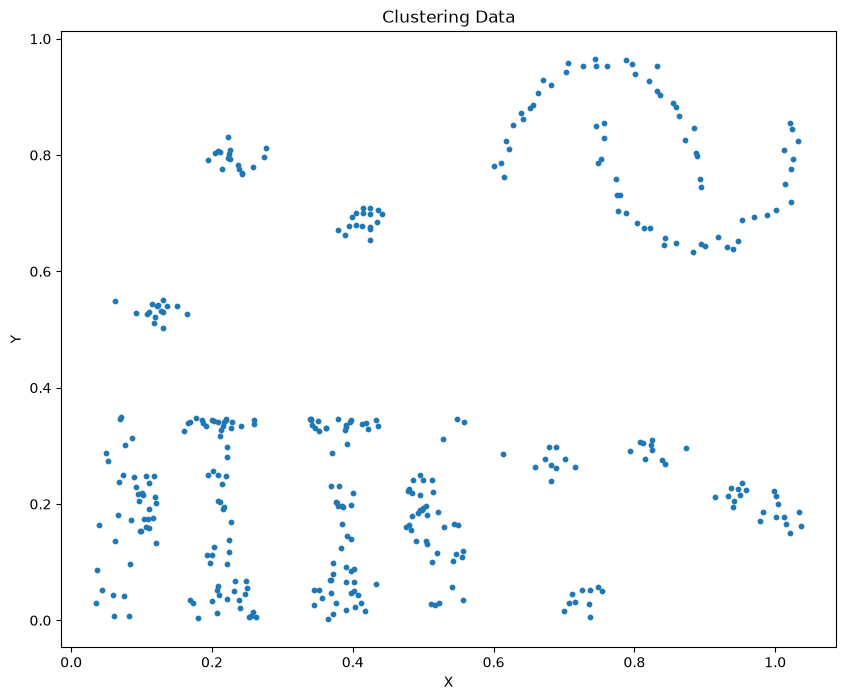

In [ ]:
def parse_clustering_data(filepath):
  points = []
  with open(filepath, 'r', encoding='utf-8') as f:
    for line in f:
      # Extract the two floating point numbers from each line
      nums = re.findall(r'[-+]?\d*\.\d+', line)
      if len(nums) >= 2:
        points.append((float(nums[0]), float(nums[1])))
  return points

data = parse_clustering_data('clustering.txt')
print(f"Loaded {len(data)} points")

xs = [p[0] for p in data]
ys = [p[1] for p in data]

plt.figure(figsize=(10, 8))
plt.scatter(xs, ys, s=10)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Clustering Data')
plt.show()

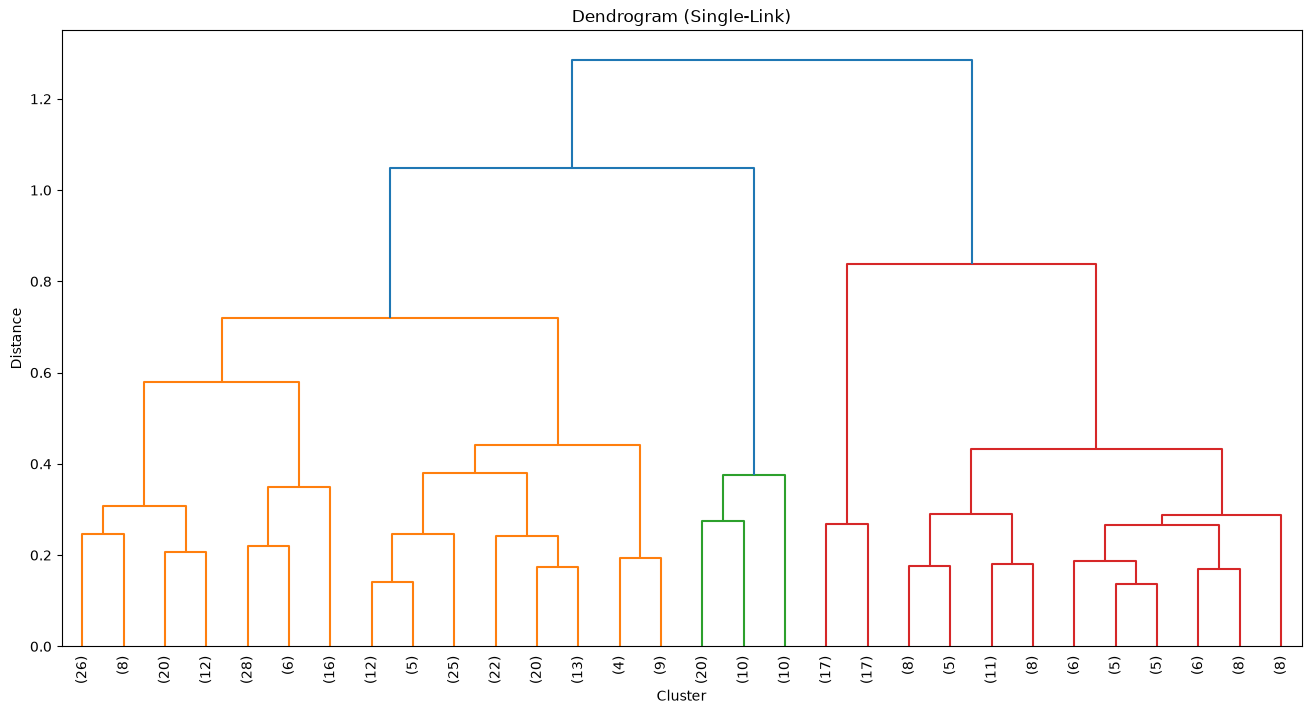

In [34]:
# Run HAC with single-link (min distance)
merge_history = hierarchical_agglomerative_clustering(data, max)

# Convert merge_history into scipy linkage matrix format
# Each row: [cluster_1_id, cluster_2_id, distance, size_of_new_cluster]
n = len(data)

# Map from our cluster sets to linkage IDs
# Original points are 0..n-1, merged clusters get IDs n, n+1, ...
cluster_to_linkage_id = {frozenset({i}): i for i in range(n)}
linkage_matrix = []

for step, merge in enumerate(merge_history):
  c1 = frozenset(merge['cluster_1'])
  c2 = frozenset(merge['cluster_2'])
  dist = merge['distance']
  new_cluster = c1 | c2

  id1 = cluster_to_linkage_id[c1]
  id2 = cluster_to_linkage_id[c2]
  new_id = n + step
  cluster_to_linkage_id[new_cluster] = new_id

  # Record the corresponds data points being merged together from each, the distance, and how many original data points make up this cluster
  linkage_matrix.append([id1, id2, dist, len(new_cluster)])

linkage_matrix = np.array(linkage_matrix)

# Plot dendrogram
plt.figure(figsize=(16, 8))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title('Dendrogram (Single-Link)')
plt.xlabel('Cluster')
plt.ylabel('Distance')
plt.show()

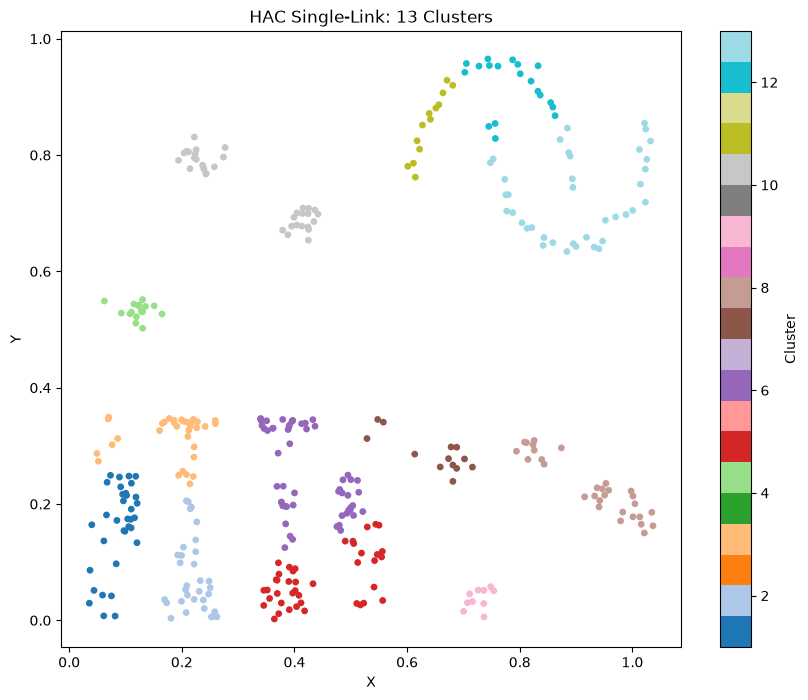

In [35]:
from scipy.cluster.hierarchy import fcluster

# Cut the dendrogram to get 13 clusters
num_clusters = 13
labels = fcluster(linkage_matrix, t=num_clusters, criterion='maxclust')

# Plot color-coded scatter
plt.figure(figsize=(10, 8))
scatter = plt.scatter(xs, ys, c=labels, cmap='tab20', s=15)
plt.colorbar(scatter, label='Cluster')
plt.xlabel('X')
plt.ylabel('Y')
plt.title(f'HAC Single-Link: {num_clusters} Clusters')
plt.show()